In [96]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from jaxopt import AndersonAcceleration
import pickle
import os
import optax
from scipy import stats
import pandas as pd
import seaborn as sns

# Model parameters
m = 2  # Number of mitral neurons (glomeruli)
x = jnp.ones(m)  # Input odour signal

In [97]:
# Naka-Rushton function

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

Note above for Naka-Rushton, floating point exponent is not defined for negative numbers (gives nan)

In [98]:


# Unpack parameters
def unpack_theta(theta, m):
    idx = 0
    w_osn_r = theta[idx:idx+m]; idx += m
    w_osn_b = theta[idx:idx+m]; idx += m
    w_osn_g = theta[idx:idx+m]; idx += m
    w_osn_y = theta[idx:idx+m]; idx += m
    w_b_r = theta[idx:idx+m]; idx += m
    w_b_g = theta[idx:idx+m]; idx += m
    w_b_y = theta[idx:idx+m]; idx += m
    w_r_y = theta[idx:idx+m]; idx += m
    w_r_g = theta[idx:idx+m]; idx += m
    alpha = theta[idx:idx+m]; idx += m
    W_g_r = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    W_g_y = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y

# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g)

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b, n_g):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    # Create a function with the n values baked in that matches AndersonAcceleration signature
    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g)

    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-8, maxiter=100)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r, n_b, n_g, n_y):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b, n_g)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


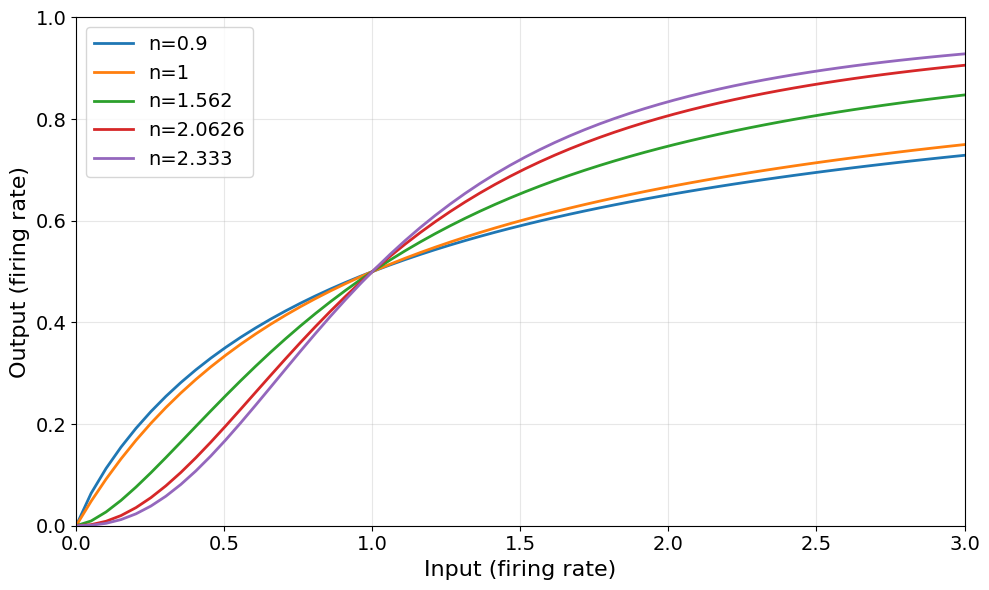

In [ ]:
# Visualise the Naka-Rushton function
x_vals = jnp.linspace(0, 5, 100)
n_values = [0.9, 1.562, 2.0626, 2.333]

plt.figure(figsize=(10, 6))
for n in n_values:
    y_vals = nr(x_vals, n=n)
    plt.plot(x_vals, y_vals, label=f'n={n}', linewidth=2)

plt.xlabel('Input (firing rate)', fontsize=16)
plt.ylabel('Output (firing rate)', fontsize=16)
plt.grid(True, alpha=0.3)
plt.xlim(0, 3)
plt.ylim(0, 1)
#plt.axhline(y=0.5, color='r', linestyle='--', alpha=0.5, label='Target firing rate (0.5)')
plt.tick_params(axis='both', direction='out', labelsize=14)
plt.legend(fontsize=14)
plt.tight_layout()
#plt.savefig(f'Figures/Naka_Rushton.eps')
plt.show()

# Parameter Initialisation

In [99]:
# set up optimisation problem
m = 2  # number of mitral neurons
n_var = 4  # r, g, b, y
n = n_var * m  # total state length
x = jnp.ones(m)  # input odour signal

# Naka-Rushton n values for each neuron type
n_r = 2.333   # red neurons (ETCs)
n_b = 0.9    # blue neurons
n_g = 2.0626  # green neurons
n_y = 1.562   # yellow/mitral neurons

# target firing rates (all neurons should fire around 0.5)
y_target = jnp.array([0.5, 0.5])  # mitral cell output
g_target = jnp.array([0.5, 0.5])  # green neurons
b_target = jnp.array([0.5, 0.5])  # blue neurons
r_target = jnp.array([0.5, 0.5])  # red neurons

# number of parameters in the model
# parameters: w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g,
#            alpha, W_g_r, W_g_y
no_params = 28  # total number of parameters

print(f"Setup:")
print(f"  - Number of mitral neurons (channels): {m}")
print(f"  - Number of parameters: {no_params}")
print(f"  - Target firing rates: {np.array(y_target)}")
print(f"  - Input signal: {np.array(x)}")
print(f"  - N values: n_r={n_r}, n_b={n_b}, n_g={n_g}, n_y={n_y}")

Setup:
  - Number of mitral neurons (channels): 2
  - Number of parameters: 28
  - Target firing rates: [0.5 0.5]
  - Input signal: [1. 1.]
  - N values: n_r=2.333, n_b=0.9, n_g=2.0626, n_y=1.562


In [100]:
# define loss function
def loss_fn(theta):
    """Loss function: sum of squared differences from target firing rates"""
    r, g, b, y = mitral_output(theta, x, m, n_r=n_r, n_b=n_b, n_g=n_g, n_y=n_y)
    loss = (jnp.sum((r - r_target) ** 2) +
            jnp.sum((g - g_target) ** 2) +
            jnp.sum((b - b_target) ** 2) +
            jnp.sum((y - y_target) ** 2))
    return loss

In [101]:
def adam_optimiser(loss_fn, theta_init, lr=0.02, steps=1500, beta1=0.9, beta2=0.999, eps=1e-8, max_grad_norm=3.0):
    """
    Adam optimiser using optax (JAX-native optimization library)
    """

    grad_fn = jax.jit(jax.grad(loss_fn))
    loss_fn_jit = jax.jit(loss_fn)

    # pre-compile functions
    _ = grad_fn(theta_init)
    _ = loss_fn_jit(theta_init)

    optimizer = optax.adam(learning_rate=lr, b1=beta1, b2=beta2, eps=eps)
    opt_state = optimizer.init(theta_init)

    loss_history = []
    theta = theta_init

    for step in range(steps):
        grad = grad_fn(theta)
        updates, opt_state = optimizer.update(grad, opt_state, theta)
        theta = optax.apply_updates(theta, updates)

        # keep weights non-negative
        theta = jnp.clip(theta, 0.0, None)

        # keep alpha between 0 and 1
        alpha_start_idx = 9 * m
        alpha_end_idx = 10 * m
        theta = theta.at[alpha_start_idx:alpha_end_idx].set(
            jnp.clip(theta[alpha_start_idx:alpha_end_idx], 0.0, 1.0)
        )

        # keep matrix diagonal to 0
        theta = theta.at[-1].set(0)
        theta = theta.at[-4].set(0)
        theta = theta.at[-5].set(0)
        theta = theta.at[-8].set(0)

        if step % 20 == 0 or step == steps - 1:
            loss_float = float(loss_fn_jit(theta))
            loss_history.append(loss_float)
    return theta, loss_history

In [109]:
# sample initial parameters
no_samples = 1000  # number of different starting points
key = jax.random.PRNGKey(0)
theta_matrix = jax.random.uniform(key, (no_samples, no_params), minval=0.0, maxval=1.0)

#for all the matrices weights , set the diagonal to 0
for i in range(no_samples):
    theta_matrix = theta_matrix.at[i, -1].set(0)
    theta_matrix = theta_matrix.at[i, -4].set(0)
    theta_matrix = theta_matrix.at[i, -5].set(0)
    theta_matrix = theta_matrix.at[i, -8].set(0)


print(f"Sampled {no_samples} initial parameter sets")
print(f"Initial parameter matrix shape: {theta_matrix.shape}")

Sampled 1000 initial parameter sets
Initial parameter matrix shape: (1000, 28)


In [110]:
# run optimisation for each sample
theta_opt = jnp.zeros((no_samples, no_params))
r_opt = jnp.zeros((no_samples, m))
g_opt = jnp.zeros((no_samples, m))
b_opt = jnp.zeros((no_samples, m))
y_opt = jnp.zeros((no_samples, m))
all_loss_histories = []

print("Running Adam optimizer...\n")

for i in range(no_samples):
    print(f"Sample {i+1}/{no_samples}:")
    theta_init = theta_matrix[i, :]
    initial_loss = loss_fn(theta_init)
    print(f"  Initial loss: {initial_loss:.6f}")

    theta_optimised, loss_history = adam_optimiser(
        loss_fn, theta_init  # Uses improved defaults: lr=0.02, steps=1500
    )
    all_loss_histories.append(loss_history)

    theta_opt = theta_opt.at[i, :].set(theta_optimised)
    r, g, b, y = mitral_output(theta_optimised, x, m, n_r=n_r, n_b=n_b, n_g=n_g, n_y=n_y)

    r_opt = r_opt.at[i, :].set(r)
    g_opt = g_opt.at[i, :].set(g)
    b_opt = b_opt.at[i, :].set(b)
    y_opt = y_opt.at[i, :].set(y)

    final_loss = loss_fn(theta_optimised)
    print(f"  Final loss: {final_loss:.6f}")
    print(f"  Output y: {np.array(y)}")
    print()



Running Adam optimizer...

Sample 1/1000:
  Initial loss: 1.309025
  Final loss: 0.000000
  Output y: [0.50000006 0.5       ]

Sample 2/1000:
  Initial loss: 1.539110
  Final loss: 0.750000
  Output y: [0. 0.]

Sample 3/1000:
  Initial loss: 1.609004
  Final loss: 0.000000
  Output y: [0.5 0.5]

Sample 4/1000:
  Initial loss: 1.366937
  Final loss: 0.250000
  Output y: [0.49999997 0.5       ]

Sample 5/1000:
  Initial loss: 1.362403
  Final loss: 0.250000
  Output y: [0.5 0.5]

Sample 6/1000:
  Initial loss: 1.477166
  Final loss: 0.500000
  Output y: [0.5 0.5]

Sample 7/1000:
  Initial loss: 1.449259
  Final loss: 0.250000
  Output y: [0.5 0. ]

Sample 8/1000:
  Initial loss: 1.565179
  Final loss: 0.250000
  Output y: [0.5 0.5]

Sample 9/1000:
  Initial loss: 1.613055
  Final loss: 1.000000
  Output y: [0. 0.]

Sample 10/1000:
  Initial loss: 1.718857
  Final loss: 0.000000
  Output y: [0.49999997 0.5       ]

Sample 11/1000:
  Initial loss: 1.436129
  Final loss: 0.000000
  Output y

/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_79109/3792512246.py:24: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()




Optimization results:
Target output: [0.5 0.5]

Optimized outputs:
  Sample 1: y = [0.50000006 0.5       ]
  Sample 2: y = [0. 0.]
  Sample 3: y = [0.5 0.5]
  Sample 4: y = [0.49999997 0.5       ]
  Sample 5: y = [0.5 0.5]
  Sample 6: y = [0.5 0.5]
  Sample 7: y = [0.5 0. ]
  Sample 8: y = [0.5 0.5]
  Sample 9: y = [0. 0.]
  Sample 10: y = [0.49999997 0.5       ]
  Sample 11: y = [0.5 0.5]
  Sample 12: y = [0.49999997 0.5       ]
  Sample 13: y = [0.5 0.5]
  Sample 14: y = [0.49999997 0.5       ]
  Sample 15: y = [0.50000006 0.50000006]
  Sample 16: y = [0.5 0.5]
  Sample 17: y = [0.5 0.5]
  Sample 18: y = [0.  0.5]
  Sample 19: y = [0.5 0. ]
  Sample 20: y = [0.5 0.5]
  Sample 21: y = [0.5 0.5]
  Sample 22: y = [0.49999997 0.5       ]
  Sample 23: y = [0.5000002 0.       ]
  Sample 24: y = [0.5 0. ]
  Sample 25: y = [0.49999997 0.50000006]
  Sample 26: y = [0.5 0.5]
  Sample 27: y = [0.50000006 0.5       ]
  Sample 28: y = [0.50000006 0.5       ]
  Sample 29: y = [0.5 0.5]
  Sample 30

In [111]:
plt.figure(figsize=(10, 6))

# keep track of the line objects so we can get their colors
lines = []

for i, loss_hist in enumerate(all_loss_histories):
    steps = np.arange(0, len(loss_hist)) * 20
    line, = plt.plot(steps, loss_hist, 'o-', linewidth=2, markersize=4)
    lines.append(line)  # store line object

plt.xlabel('Iteration', fontsize=24)
plt.ylabel('Loss', fontsize=24)
plt.yscale('log')
#plt.xlim(0, 500)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.grid(True, alpha=0.3)

# create legend using the colors of the actual plotted lines
legend_handles = [Patch(color=line.get_color(), label=f'Set {i+1}')
                  for i, line in enumerate(lines)]
plt.legend(handles=legend_handles,loc='upper right',  fontsize=18)

plt.tight_layout()
#plt.savefig('Figures/loss_convergence.eps')
plt.show()

print("Optimization results:")
print(f"Target output: {np.array(y_target)}")
print(f"\nOptimized outputs:")
for i in range(y_opt.shape[0]):
    print(f"  Sample {i+1}: y = {np.array(y_opt[i])}")

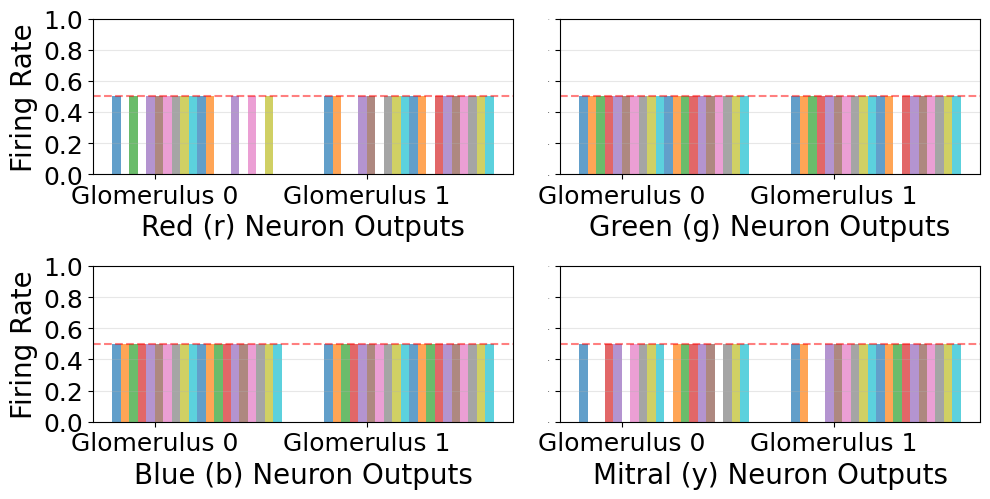

In [107]:

###############################
# plot the output values of r, g, b, y for all samples
plt.figure(figsize=(10, 6))

# create subplots for each neuron type
neuron_types = ['Red (r)', 'Green (g)', 'Blue (b)', 'Mitral (y)']
outputs = [r_opt, g_opt, b_opt, y_opt]

for idx, (neuron_type, output) in enumerate(zip(neuron_types, outputs)):
    plt.subplot(2, 2, idx + 1)

    x_pos = np.arange(m)
    width = 0.8 / y_opt.shape[0]

    # plot bars for each sample with multicolored coding
    for i in range(y_opt.shape[0]):
        plt.bar(x_pos + i*width, np.array(output[i]), width,
                label=f'Sample {i+1}' if idx == 0 else '', alpha=0.7)

    # add target line at 0.5
    plt.axhline(y=0.5, color='red', linestyle='--', linewidth=1.5,
                alpha=0.5, label='Target (0.5)')

    # Y-axis
    # only for the left plots
    if idx == 0 or idx == 2 :
        plt.ylabel('Firing Rate', fontsize=20)
        plt.yticks(fontsize=18)
    else:
        plt.yticks(fontsize=0)

    # subplot x-axis ticks
    plt.xticks(x_pos + 4.5*width, [f'Glomerulus {j}' for j in range(m)], fontsize=14)
    plt.xlabel(f'{neuron_type} Neuron Outputs', fontsize=20)
    plt.xticks(fontsize=18)
    plt.ylim([0, 1.0])
    plt.grid(True, alpha=0.3, axis='y')

# legend only once
# central x-axis label for the whole figure
plt.tight_layout(rect=[0, 0.1, 1, 0.95])
#plt.savefig('Figures/neuron_outputs_rgby.eps')
plt.show()




In [112]:
def check_single_theta_np(theta, x, m):
    """Check single theta sample - using numpy for compatibility"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_g, n_y)
    # Convert to numpy arrays
    r = np.array(r)
    g = np.array(g)
    b = np.array(b)
    y = np.array(y)

    # Check if all elements are in [0.4, 0.6]
    r_ok = (r >= 0.4).all() and (r <= 0.6).all()
    g_ok = (g >= 0.4).all() and (g <= 0.6).all()
    b_ok = (b >= 0.4).all() and (b <= 0.6).all()
    y_ok = (y >= 0.4).all() and (y <= 0.6).all()

    return r_ok and g_ok and b_ok and y_ok

# Process samples
n_samples = theta_opt.shape[0]
valid_mask = np.zeros(n_samples, dtype=bool)

for i in range(n_samples):
    theta_star = jnp.array(theta_opt[i, :])
    valid_mask[i] = check_single_theta_np(theta_star, x, m)

    if (i + 1) % 100 == 0:
        print(f"Processed {i+1}/{n_samples} samples...")

theta_opt = theta_opt[valid_mask]

print(f"Number of valid theta_opt: {theta_opt.shape[0]} out of {n_samples}")

# save theta_opt as pickle file
# create Theta_opt directory if it doesn't exist
os.makedirs('Theta_opt', exist_ok=True)

with open(f'Theta_opt/theta_opt_{theta_opt.shape[0]}_samples_n_different.pkl', 'wb') as f:
    pickle.dump(theta_opt, f)

Processed 100/1000 samples...
Processed 200/1000 samples...
Processed 300/1000 samples...
Processed 400/1000 samples...
Processed 500/1000 samples...
Processed 600/1000 samples...
Processed 700/1000 samples...
Processed 800/1000 samples...
Processed 900/1000 samples...
Processed 1000/1000 samples...
Number of valid theta_opt: 332 out of 1000
